# ランダムフォレスト
たくさんの決定木を作って多数決で予測する「ランダムフォレスト」を学びます。1本の決定木より過学習しにくく、精度が安定することを確かめます。また、どの特徴量が予測に役立っているか(特徴量の重要度)を調べます。

## 学習目標
- ランダムフォレストのしくみ(多数の決定木の多数決)を説明できる
- `RandomForestClassifier` を学習させ、決定木と精度を比べられる
- `max_depth` などで、ランダムフォレストの過学習を抑えられる
- `feature_importances_` で特徴量の重要度を調べ、グラフにできる

## ランダムフォレストのしくみ

1本の決定木は、学習用のデータの細かい特徴まで覚えてしまい、過学習しやすいモデルでした。ランダムフォレストは、次の工夫で多数の **少しずつ違う決定木** を作り、その **多数決** で予測します。

| 工夫 | 内容 |
|---|---|
| データのランダムな選び直し | 木ごとに、学習用のデータから重複を許してランダムに選び直したデータで学習する |
| 特徴量のランダムな選択 | 木の各分岐で、ランダムに選んだ一部の特徴量の中から質問を選ぶ |

1本1本の木はそれぞれ違う間違いをしますが、多数決をとると間違いが打ち消し合い、精度が安定します。

In [1]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# 特徴量の表を読み込み、学習用と検証用に分ける(これまでと同じ分け方)
df = pd.read_csv("train_prepared.csv")
X = df.drop(columns=["PassengerId", "Survived"])
y = df["Survived"]
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)

# 100 本の決定木からなるランダムフォレスト(各木の深さは制限しない)
forest = RandomForestClassifier(n_estimators=100, random_state=0)
forest.fit(X_train, y_train)
print("制限なし : 学習用", round(forest.score(X_train, y_train), 3), " 検証用", round(forest.score(X_valid, y_valid), 3))

# 各木の深さを 5 までに制限したランダムフォレスト
forest5 = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=0)
forest5.fit(X_train, y_train)
print("深さ 5 まで: 学習用", round(forest5.score(X_train, y_train), 3), " 検証用", round(forest5.score(X_valid, y_valid), 3))

制限なし : 学習用 0.978  検証用 0.771
深さ 5 まで: 学習用 0.837  検証用 0.812


- 木の深さを制限しないと、学習用の正解率は 97.8% と高い一方、検証用は 77.1% で、まだ過学習気味です(それでも 1本の木の 73.1% よりは高い)
- 木の深さを 5 までに制限すると、学習用は 83.7% に下がり、検証用は 81.2% に上がりました。これまでのモデルで最も高い正解率です

ランダムフォレストでも、決定木と同じハイパーパラメータ(`max_depth`・`min_samples_leaf`)で各木の複雑さを調整できます。`n_estimators` は木の本数で、多いほど精度は安定しますが、学習に時間がかかります。

## 特徴量の重要度

ランダムフォレストは、学習後に `feature_importances_` で **特徴量の重要度**(その特徴量での分岐が、予測の改善にどれだけ役立ったか。合計は 1)を求められます。

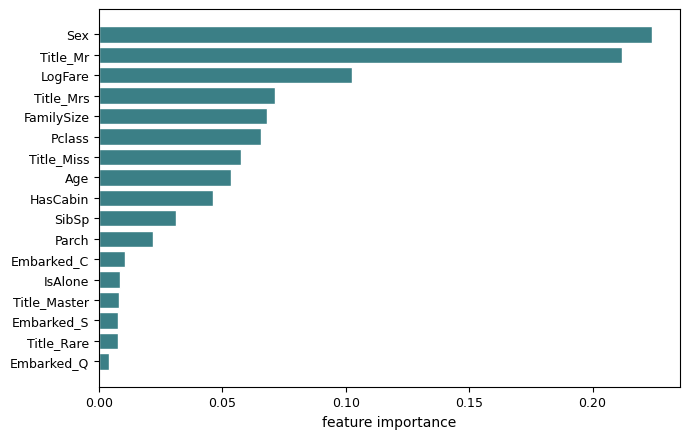

In [2]:
import matplotlib.pyplot as plt

# 重要度を、特徴量の名前を付けた Series にして、小さい順に並べる(横棒グラフで上が大きくなるように)
importance = pd.Series(forest5.feature_importances_, index=X.columns).sort_values()

# 横棒グラフにする
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(importance.index, importance.values)
ax.set_xlabel("feature importance")
fig.tight_layout()
plt.show()

`Sex`(性別)と `Title_Mr`(成人男性の敬称)の重要度が特に高く、次に `LogFare`(運賃)が続きます。前の講座の分析で見つけた「性別」「等級・運賃」が、モデルでも重要な特徴量になっています。

**注意**:`Sex` と `Title_Mr` のように互いに関係の強い特徴量は、重要度が分け合われます。重要度が低い特徴量でも、関係の強い別の特徴量があるために低く出ていることがあります。

## 演習

各木の深さを **7 まで** に制限したランダムフォレスト(木の本数 100、`random_state=0`)を学習させ、学習用と検証用の正解率を、この順に小数第3位まで表示してください。

In [ ]:
# @starter
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# 特徴量の表を読み込み、学習用と検証用に分ける
df = pd.read_csv("train_prepared.csv")
X = df.drop(columns=["PassengerId", "Survived"])
y = df["Survived"]
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)

# 木の本数 100、各木の深さを 7 までにしたランダムフォレストを作り、学習させる
# (____ に、木の本数と深さの上限を指定する引数を書く)
forest = RandomForestClassifier(____, random_state=0)
forest.fit(X_train, y_train)

# 学習用・検証用の正解率を表示する
print(round(forest.score(X_train, y_train), 3))
print(round(forest.score(X_valid, y_valid), 3))

In [3]:
# @solution
# @title: 深さ 7 のランダムフォレスト
# @hint: RandomForestClassifier(n_estimators=100, max_depth=7, random_state=0) のように指定します。
# @explanation: 学習用は 87.6%、検証用は 81.2% です。深さ 5 のとき(学習用 83.7%、検証用 81.2%)と比べると、検証用の正解率は同じで、学習用だけが上がっています。学習用と検証用の差が広がるので、この場合は深さ 5 の方が過学習の心配が少ないモデルといえます。
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# 特徴量の表を読み込み、学習用と検証用に分ける
df = pd.read_csv("train_prepared.csv")
X = df.drop(columns=["PassengerId", "Survived"])
y = df["Survived"]
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)

# 木の本数 100(n_estimators)、各木の深さを 7 まで(max_depth)にしたランダムフォレスト
forest = RandomForestClassifier(n_estimators=100, max_depth=7, random_state=0)
forest.fit(X_train, y_train)

# 学習用・検証用の正解率を表示する
print(round(forest.score(X_train, y_train), 3))
print(round(forest.score(X_valid, y_valid), 3))

0.876
0.812


解説の深さ 5 のランダムフォレストについて、特徴量の重要度が **大きい順に上位 5 つ** を、小数第3位まで表示してください。

In [ ]:
# @starter
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# 特徴量の表を読み込み、学習用と検証用に分ける
df = pd.read_csv("train_prepared.csv")
X = df.drop(columns=["PassengerId", "Survived"])
y = df["Survived"]
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)

# 深さ 5 のランダムフォレストを学習させる
forest = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=0).fit(X_train, y_train)

# 重要度を、特徴量の名前を付けた Series にする(____ に、重要度が入っている属性の名前を入れる)
importance = pd.Series(forest.____, index=X.columns)

# 大きい順に並べて、上位 5 つを小数第3位まで表示する
print(importance.sort_values(ascending=False).head(5).round(3))

In [4]:
# @solution
# @title: 重要度の上位 5 つ
# @hint: 学習したランダムフォレストの feature_importances_ に、特徴量の重要度が入っています。
# @explanation: 上位 5 つは Sex・Title_Mr・LogFare・Title_Mrs・FamilySize です。性別と敬称(性別・年齢層の情報を持つ)で上位を占め、運賃と家族の人数が続きます。
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# 特徴量の表を読み込み、学習用と検証用に分ける
df = pd.read_csv("train_prepared.csv")
X = df.drop(columns=["PassengerId", "Survived"])
y = df["Survived"]
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)

# 深さ 5 のランダムフォレストを学習させる
forest = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=0).fit(X_train, y_train)

# feature_importances_ の重要度を、特徴量の名前を付けた Series にする
importance = pd.Series(forest.feature_importances_, index=X.columns)

# 大きい順に並べて、上位 5 つを小数第3位まで表示する
print(importance.sort_values(ascending=False).head(5).round(3))

Sex           0.224
Title_Mr      0.212
LogFare       0.102
Title_Mrs     0.071
FamilySize    0.068
dtype: float64


<!-- @question
type: choice
answer: それぞれ少しずつ違う多数の木の予測を多数決でまとめるので、1本の木の偶然の間違いが打ち消し合うため。
title: ランダムフォレストが安定する理由
hint: ランダムフォレストは、データと特徴量をランダムに選び直して、少しずつ違う木を多数作ります。
explanation: 1本の決定木は、学習用のデータの偶然のばらつきまで覚えてしまいます。ランダムフォレストは、データと特徴量をランダムに選び直して作った多数の木の多数決をとるので、1本1本の偶然の間違いが打ち消し合い、新しいデータでの精度が安定します。木の数を増やしても、学習用のデータの量が増えるわけではありません。
-->
ランダムフォレストが、1本の決定木より過学習しにくい理由として最も適切なものを選べ。

- 木の数だけ学習用のデータが増えるため。
- それぞれ少しずつ違う多数の木の予測を多数決でまとめるので、1本の木の偶然の間違いが打ち消し合うため。
- ランダムフォレストの木は、必ず深さ 1 になるため。
- 特徴量の重要度が低い特徴量を、自動的に取り除くため。

## まとめ

- ランダムフォレストは、データと特徴量をランダムに選び直して作った多数の決定木の多数決で予測する。1本の決定木より過学習しにくい。
- `n_estimators`(木の本数)・`max_depth` などで調整する。深さ 5 のランダムフォレストで検証用の正解率 81.2%。
- `feature_importances_` で特徴量の重要度がわかる。性別・敬称・運賃の重要度が高い。関係の強い特徴量どうしは重要度を分け合うことに注意する。